# DFA Cluster Analysis

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import silhouette_score
import scipy
from scipy.stats import randint, uniform, loguniform, spearmanr
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist, squareform
from lib.superdataset_utils import (
    load_superdataset,
    DFS_QUESTION_COLS, 
    IDAF_QUESTION_COLS
)

In [3]:
print(f'pandas version: {pd.__version__}')
print(f'numpy version: {np.__version__}')
print(f'matplotlib version: {matplotlib.__version__}')
print(f'sklearn version: {sklearn.__version__}')
print(f'scipy version: {scipy.__version__}')

pandas version: 2.3.3
numpy version: 2.4.6
matplotlib version: 3.10.6
sklearn version: 1.9.1
scipy version: 1.15.3


---

## Helper functions

In [23]:
def stability(X, Z, k, B=50, method="average", metric="cityblock", seed=0):
    """Mean and SD of bootstrap ARI between the full-data k-cluster solution and resample solutions."""
    rng = np.random.default_rng(seed)
    ref = fcluster(Z, k, criterion="maxclust")
    aris = []
    for _ in range(B):
        idx = np.unique(rng.choice(len(X), size=len(X), replace=True))
        Zb = linkage(pdist(X.iloc[idx].to_numpy(), metric=metric), method=method)
        aris.append(adjusted_rand_score(ref[idx], fcluster(Zb, k, criterion="maxclust")))
    return np.mean(aris), np.std(aris)

---

## Load superdataset

In [4]:
super_df = load_superdataset('./DFA-data/merged_dfa_data_cleaned_2026_09_17.csv')
super_df.shape

(10163, 64)

In [5]:
super_df.columns

Index(['Participant_id', 'Last_Dental_Visit', 'Sex', 'Age', 'agegrp',
       'Ethnicity_new', 'Race', 'dfs1', 'dfs2', 'dfs3', 'dfs4', 'dfs5', 'dfs6',
       'dfs7', 'dfs8', 'dfs9', 'dfs10', 'dfs11', 'dfs12', 'dfs13', 'dfs14',
       'dfs15', 'dfs16', 'dfs17', 'dfs18', 'dfs19', 'dfs20', 'idaf1a',
       'idaf1b', 'idaf1c', 'idaf1d', 'idaf1e', 'idaf1f', 'idaf1g', 'idaf1h',
       'idaf2a', 'idaf2b', 'idaf2c', 'idaf2d', 'idaf2e', 'idaf3a', 'idaf3b',
       'idaf3c', 'idaf3d', 'idaf3e', 'idaf3f', 'idaf3g', 'idaf3h', 'idaf3i',
       'idaf3j', 'mdas1', 'mdas2', 'mdas3', 'mdas4', 'mdas5', 'source',
       'count_missing', 'dfs_flag', 'idaf_flag', 'mdas_flag',
       'dfs_total_score', 'dfs_avoidance_fear', 'dfs_specific_stimuli_fear',
       'dfs_physiological_arousal'],
      dtype='object')

In [6]:
# subset data to dfs questions
subset_df = super_df[DFS_QUESTION_COLS]
subset_df.shape

(10163, 20)

---

## Load records with both a DFS and IDFA

In [7]:
subset_df = super_df.query("dfs_flag==1 and idaf_flag==1")
subset_df.shape

(738, 64)

In [8]:
# include only the DFS and IDFA question columns
subset_df = subset_df[DFS_QUESTION_COLS + IDAF_QUESTION_COLS]

# drop IDFA "specific phobias" columns - they have binary values
subset_df = subset_df.drop(['idaf2a', 'idaf2b', 'idaf2c','idaf2d', 'idaf2e'], axis=1)
subset_df.shape

(738, 38)

In [20]:
# drop missing rows with missing values
subset_df = subset_df[(subset_df >0).all(axis=1)].reset_index(drop=True)
subset_df.shape

(724, 38)

---

## Cluster data 
note: 'idaf2a', 'idaf2b', 'idaf2c','idaf2d', 'idaf2e' (specific phobias) are not included

### Respondent clustering  
Group respondents by how similar their answers are, then checks how well the result holds up for 2 to 7 clusters.  
1. `pdist(..., "cityblock")` computes the Manhattan distance between every pair of respondents: the sum of their absolute differences across the items.  
2. `linkage(D, "average")` builds a tree by repeatedly merging the two closest groups, using the average distance between their members.  
3. `cophenet(Z, D)` checks how well the tree preserves the original distances. A value of about 0.7 or higher means the tree is a faithful summary.  
4. The loop over k = 2 to 7 does three things each time:
  * `fcluster` cuts the tree into k clusters.
  * `silhouette_score` measures how well separated those clusters are, from −1 to 1, where higher is better.
  * `np.bincount` reports the cluster sizes.

To pick k, look for a high silhouette score where no cluster is trivially small.  

#### Why range 2 to 7  
The range 2 to 7 is a conventional choice chosen by Claude.  

* **Lower bound of 2:** k = 1 means no clustering, and silhouette is undefined for a single cluster, so 2 is the smallest value you can score.  
* **Upper bound of 7:** this is a practical limit on interpretability. Profiles of fear-survey subgroups in the literature usually have about 2 to 5 groups, and more than 6 or 7 are hard to describe or defend clinically.

The output also supported stopping there. By k = 4 or 5 the new clusters had only 3 to 14 members, the outliers that average linkage splits off, and the silhouette score kept falling. Going higher would only have split off more small groups.  

If you want to check that nothing interesting appears beyond 7, extend the loop to range(2, 16) and look for a jump in silhouette or a split of one of the large clusters. With average linkage on this data, you will most likely see more small outlier groups.  

In [18]:
D = pdist(subset_df.to_numpy(), metric="cityblock")  # Manhattan suits ordinal Likert
Z = linkage(D, method="average")                     # or: linkage(X, "ward") for Euclidean/Ward
print("cophenetic r:", cophenet(Z, D)[0])           # how faithfully the tree preserves distances

for k in range(2, 8):
    lab = fcluster(Z, k, criterion="maxclust")
    print(k, round(silhouette_score(squareform(D), lab, metric="precomputed"), 3),
          np.bincount(lab)[1:])

cophenetic r: 0.8058154603391688
2 0.451 [484 240]
3 0.379 [484  10 230]
4 0.335 [  2 482  10 230]
5 0.328 [  2 482  10 162  68]
6 0.323 [  2 482  10 162   2  66]
7 0.314 [  2 482  10 161   1   2  66]


#### Interpreting the output  
**Overall fit:** A cophenetic r of 0.81 means the tree summarizes the distances well.

**k = 2 (silhouette 0.45):** 484 vs 240. This is moderate, real structure and the best-separated solution. It is very likely a low-fear vs. high-fear split. The high-fear share is larger here (33% vs 21%). That fits this subsample (respondents who completed IDAF part 2), which may be enriched for fearful people if part 2 was skip-logic gated.  

**k = 3 to 4:** A 10-person group, then a 2-person group, are split off. These are unusual response patterns, not subtypes. The group of 10 could be a coherent minority, such as high stimulus fear with no avoidance.  

**k = 5:** This is the first substantive split since k = 2. The high-fear group of 240 divides into 162 and 68. It mirrors the 600/282 split in the full DFS data, and is the result most worth examining. Silhouette here is 0.33, which means weak but present structure.  

**k = 6 to 7:** These only add groups of 1 or 2 people.  

What to report:  
* **k = 2** is the primary, well-supported solution.
* **k = 5** is a candidate refinement within the high-fear group.

### Profile the clusters to see whether the 162 and 68 groups differ in level or in shape.  
* **Same pattern, different height** (all items higher in one group): it’s a severity gradient.
* **Different items elevated:** For example, one group high on needle/drill items (dfs14–18, idaf3h) and the other high on avoidance and anticipation (dfs1–2, dfs8–13, idaf1b/1g). That would be a subtype. It would also match the item-cluster structure you already found.

In [49]:
lab5 = fcluster(Z, 5, "maxclust")
prof = subset_df.groupby(lab5).mean().T.round(2)
prof.loc["n"] = np.bincount(lab5)[1:]
prof.tail()

,1,2,3,4,5
idaf3g,1.0,2.48,3.5,3.52,3.93
idaf3h,1.0,2.12,2.1,3.98,4.53
idaf3i,1.0,1.47,1.7,2.88,3.84
idaf3j,1.0,1.73,3.2,2.89,4.13
n,2.0,482.00,10.0,162.00,68.00


In [50]:
prof.to_csv('k5-cluster-profile.csv') # save profile results

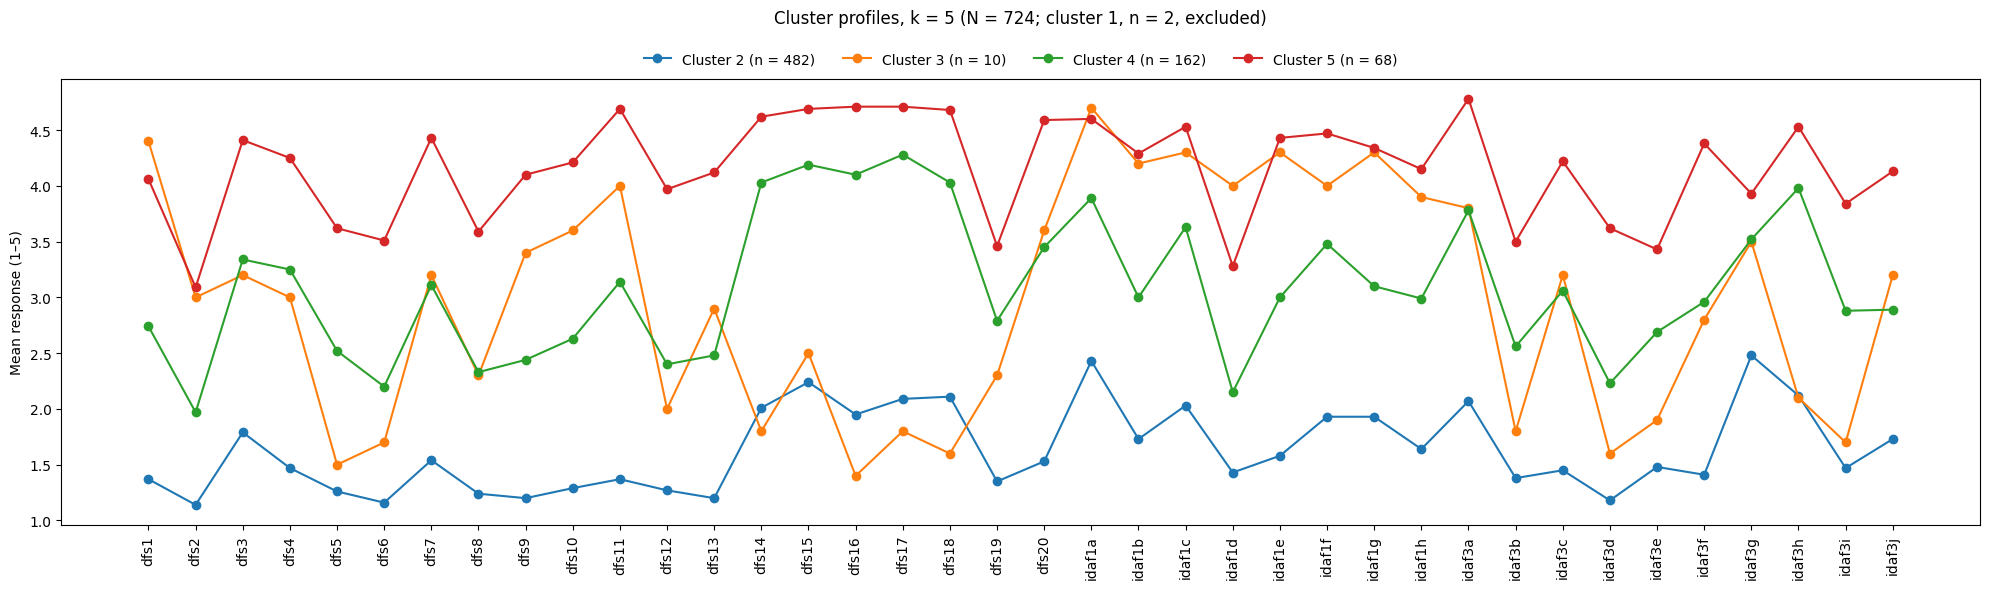

In [87]:
sizes = prof.loc["n"] if "n" in prof.index else pd.Series(np.bincount(lab5)[1:], index=prof.columns)
plot_df = prof.drop(index="n", errors="ignore").drop(columns=1)

ax = plot_df.plot(figsize=(20, 6), marker="o")
ax.set_xticks(range(len(plot_df))); ax.set_xticklabels(plot_df.index, rotation=90)
ax.set_ylabel("Mean response (1–5)")
ax.set_title(f"Cluster profiles, k = 5 (N = {int(sizes.sum())}; cluster 1, n = {int(sizes[1])}, excluded)", pad=40)

# ax.legend([f"Cluster {c} (n = {int(sizes[c])})" for c in plot_df.columns], title="Cluster")
ax.legend(
    [f"Cluster {c} (n = {int(sizes[c])})" for c in plot_df.columns],
    # title="Cluster", 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.0),      
    ncol=len(plot_df.columns), 
    frameon=False
)
plt.tight_layout()
plt.savefig('figures/profile_analysis.png')
plt.show()

#### Visualize clusters 4 & 5

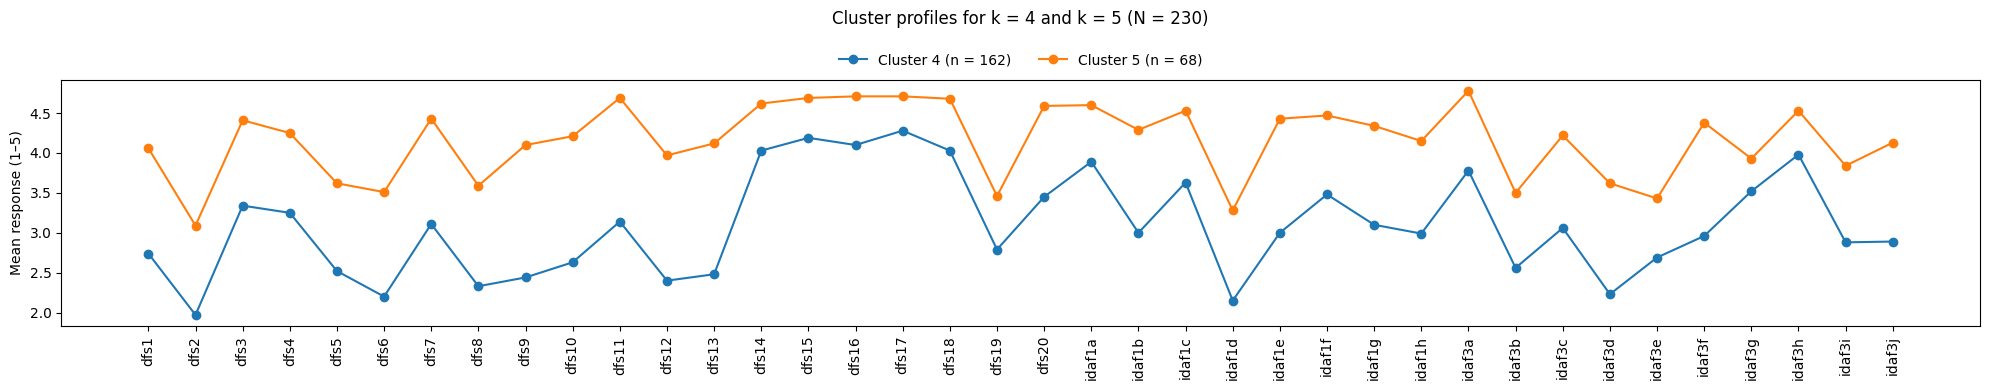

In [88]:
sizes = prof.loc["n"] if "n" in prof.index else pd.Series(np.bincount(lab5)[1:], index=prof.columns)
plot45_df = prof.drop(index="n", errors="ignore")[[4,5]]

ax = plot45_df.plot(figsize=(20, 4), marker="o")
ax.set_xticks(range(len(plot45_df))); ax.set_xticklabels(plot45_df.index, rotation=90)
ax.set_ylabel("Mean response (1–5)")
ax.set_title(f"Cluster profiles for k = 4 and k = 5 (N = {int(sizes[3:].sum())})", pad=40)

ax.legend(
    [f"Cluster {c} (n = {int(sizes[c])})" for c in plot45_df.columns],
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.0),      
    ncol=len(plot_df.columns), 
    frameon=False
)
plt.tight_layout()
plt.savefig('figures/profile_analysis_clusters_4_5.png')
plt.show()

#### Compare clusters 4 & 5  
Clusters 4 & 5 seem visually similar. Compare similarities by plitting the difference between two profiles into three parts:
* **Level (elevation):** is one profile simply higher overall?
* **Scatter:** does one profile vary more from item to item?
* **Shape (pattern):** do the profiles rise and fall on the same items?

#### Descriptive measures from the mean profiles 
How to interpret it:
* **Shape correlation:** a value above 0.8 means the profiles move together.
* **SD of the differences:** if cluster 5 is cluster 4 shifted up, every item gets about the same boost, so the differences are nearly constant and their SD is small.
* **The decomposition:** if elevation accounts for most of D², say 80% or more, the clusters differ mainly in severity.

In [79]:
a, b = plot45_df[4], plot45_df[5]
k = len(a)

r = np.corrcoef(a, b)[0, 1]                # shape similarity, ignores level and spread
d = b - a
print(f"shape r = {r:.3f}")
print(f"mean level difference = {d.mean():.2f}   SD of differences = {d.std():.2f}")

# Cronbach–Gleser decomposition of D² = Σ(b − a)²
sa, sb = a.std(ddof=0), b.std(ddof=0)
elev    = k * d.mean()**2
scatter = k * (sa - sb)**2
shape   = 2 * k * sa * sb * (1 - r)
D2 = elev + scatter + shape
print(pd.Series({"elevation": elev, "scatter": scatter, "shape": shape}) / D2)   # proportions

shape r = 0.837
mean level difference = 1.07   SD of differences = 0.35
elevation    0.903782
scatter      0.022465
shape        0.073753
dtype: float64


Cluster 5 is mostly a more severe version of cluster 4, not a different type of fear.

**Reading the numbers**

* **Shape r = 0.84:** the two profiles rise and fall on largely the same items.
* **Elevation = 90% of the squared distance:** almost all of the difference between the clusters is overall level. Cluster 5 is about 1.07 points higher on average.
* **SD of differences = 0.35:** the boost is fairly consistent across items. Most items differ by roughly 0.7 to 1.4 points.
* **Scatter = 2%:** both clusters spread across items to about the same degree.
* **Shape = 7%:** a small part of the difference is pattern, not level.

That 7% is understated, if anything. Cluster 5 sits at the ceiling on the needle and drill items (about 4.7), so it can’t rise as much there as on other items. That ceiling effect itself creates some apparent non-parallelism.

#### Cluster 3 seems most different  
Check cluster 3 against cluster 4.  
A low or negative shape correlation, with shape making up a large share of the squared distance, would confirm that the avoidant-anticipatory pattern is different in kind. Cluster 3 has only 10 people, so bootstrap that correlation before relying on it.

In [84]:
a, b = plot_df[4], plot_df[3]
k = len(a)

r = np.corrcoef(a, b)[0, 1]                # shape similarity, ignores level and spread
d = b - a
print(f"shape r = {r:.3f}")
print(f"mean level difference = {d.mean():.2f}   SD of differences = {d.std():.2f}")

# Cronbach–Gleser decomposition of D² = Σ(b − a)²
sa, sb = a.std(ddof=0), b.std(ddof=0)
elev    = k * d.mean()**2
scatter = k * (sa - sb)**2
shape   = 2 * k * sa * sb * (1 - r)
D2 = elev + scatter + shape
print(pd.Series({"elevation": elev, "scatter": scatter, "shape": shape}) / D2)   # proportions

shape r = 0.019
mean level difference = -0.12   SD of differences = 1.18
elevation    0.011133
scatter      0.098448
shape        0.890419
dtype: float64


#### Uncertainty: bootstrap the shape correlation (clusters 4 & 5)
Resamples respondents within each cluster and recomputes the correlation each time.

In [80]:
items = plot45_df.index
X4 = subset_df.loc[lab5 == 4, items].to_numpy()
X5 = subset_df.loc[lab5 == 5, items].to_numpy()
rng = np.random.default_rng(0)
boot = [np.corrcoef(X4[rng.integers(0, len(X4), len(X4))].mean(0),
                    X5[rng.integers(0, len(X5), len(X5))].mean(0))[0, 1] for _ in range(2000)]
print("shape r 95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

shape r 95% CI: [0.707 0.873]


The shape similarity holds up under resampling. Even the low end of the interval (0.71) is a strong correlation, so the conclusion that cluster 5 is mostly a more severe cluster 4 does not depend on which respondents happen to be in the sample.

#### Testing parallelism  
Subtract each person’s own mean from their responses, which removes level. Then use a permutation test to ask whether the two clusters’ adjusted mean profiles differ more than random group assignments would produce.  

`dev` lists the items where cluster 5 is relatively higher or lower than its overall shift would predict. From your plot, expect cluster 5 to stand out on avoidance (dfs1–2) and on disgust and embarrassment (idaf3b, 3d, 3i, dfs6). Expect it to fall below the parallel line on needles and drills, where it’s already near the ceiling.

**Two caveats**  

* **Ceiling effect:** cluster 5 sits around 4.6–4.7 on the stimulus items, with a maximum of 5. It can’t rise as much there as on other items, so the profiles can’t be perfectly parallel even if the underlying fear is. This deflates the shape similarity, so rely more on the correlation than on the parallelism test.
* **Circularity:** the clusters were formed to differ on these same items. Treat the permutation p-value as descriptive, not inferential. A firm conclusion needs a replication sample, or the same pattern turning up in LCA classes.

In [85]:
def ipsatize(X): return X - X.mean(1, keepdims=True)
Y = np.vstack([ipsatize(X4), ipsatize(X5)]); g = np.r_[np.zeros(len(X4)), np.ones(len(X5))]
stat = lambda g: ((Y[g == 0].mean(0) - Y[g == 1].mean(0))**2).sum()
obs = stat(g)
perm = [stat(rng.permutation(g)) for _ in range(5000)]
print(f"shape-difference statistic = {obs:.5f}, permutation p = {np.mean(np.array(perm) >= obs):.5f}")

# which items depart most from parallel
dev = pd.Series(Y[g == 1].mean(0) - Y[g == 0].mean(0), index=items).sort_values()
print(dev.round(3))

shape-difference statistic = 4.67862, permutation p = 0.00000
idaf3g   -0.670
dfs17    -0.643
dfs15    -0.565
idaf3h   -0.524
dfs14    -0.485
dfs16    -0.471
dfs18    -0.426
dfs19    -0.406
idaf1a   -0.357
idaf3e   -0.336
idaf1c   -0.172
idaf3b   -0.133
idaf3i   -0.110
idaf1f   -0.076
idaf3a   -0.076
dfs4     -0.068
dfs3      0.001
dfs5      0.021
dfs2      0.048
idaf1d    0.060
dfs20     0.066
idaf3c    0.087
idaf1h    0.088
idaf1g    0.168
idaf3j    0.172
dfs8      0.183
idaf1b    0.223
dfs6      0.240
dfs7      0.244
dfs1      0.247
idaf3d    0.318
idaf3f    0.354
idaf1e    0.355
dfs11     0.484
dfs12     0.504
dfs10     0.505
dfs13     0.565
dfs9      0.587
dtype: float64


The profiles of clusters 4 and 5 are not perfectly parallel: there is a real shape difference. It’s small compared with the difference in level, and it points somewhere slightly different

**The test**

None of the 5,000 permutations reached the observed statistic, so report it as p < 0.0002 rather than 0.0000. With about 230 respondents, even a modest shape difference is detectable. This fits the earlier decomposition: shape made up about 7% of the squared distance, small but real. The circularity caveat still applies (the clusters were built from these same items), so treat the p-value as descriptive.

**Interpretation**

What cluster 4 fears is the procedures. Cluster 5 shares that fear, already near the ceiling. What it adds is fear of the whole dental context: getting to the office, the waiting room, the chair, the smell, seeing the dentist. It also adds more avoidance, uncertainty and disgust. The move from moderate to severe fear looks like generalization, from specific procedures to everything around the visit.

Two parts of the pattern need qualifying:

* **Needle and drill items:** these are negative partly because of the ceiling. Cluster 5 is at about 4.7 and can’t rise much further, so those values understate its fear.
* **Cost:** it barely changes with severity, which fits the item clustering, where cost was separate from fear.

---

### Item clustering: distance = 1 - Spearman correlation

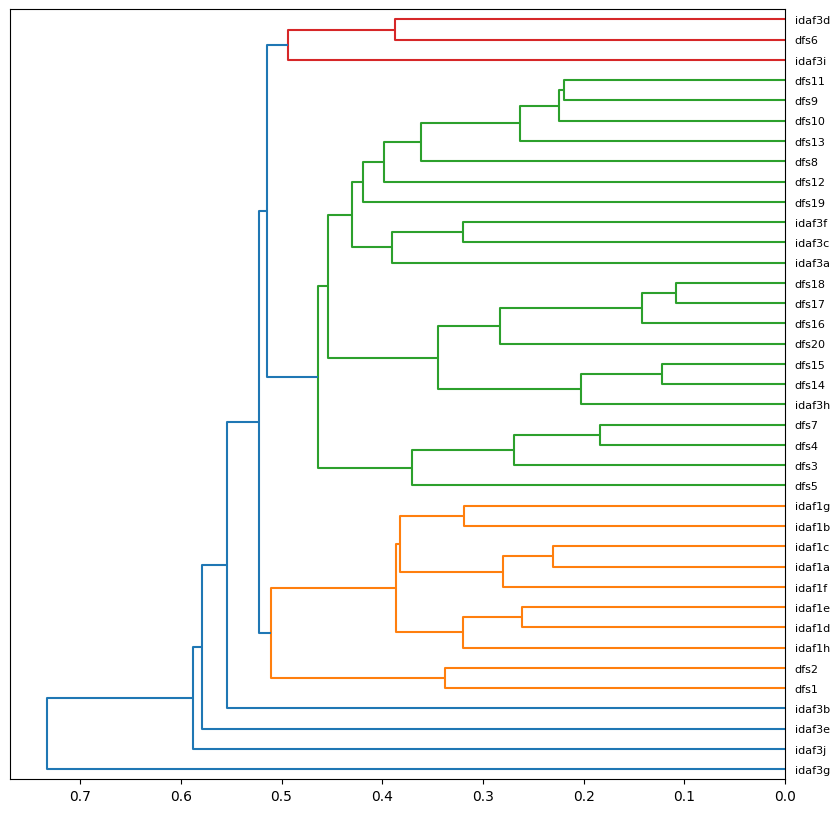

In [86]:
R = subset_df.corr(method="spearman")
Zi = linkage(squareform(1 - R, checks=False), method="average")
fig, ax = plt.subplots(figsize=(10, 10))          # width, height in inches
dendrogram(Zi, labels=subset_df.columns, orientation="left", ax=ax)
plt.savefig('figures/dfs_idaf_item_dendrogram.png')
plt.show()

---

## Hierarchical Clustering of DFS and IDAF-4C+ Items

*Interpretation of the item-level dendrogram — Ontology of Dental Care-Related Fear and Anxiety (ODFA)*

## Analysis

Items from the Dental Fear Survey (DFS, items 1–20) and the Index of Dental Anxiety and Fear (IDAF-4C+) were clustered using average-linkage hierarchical clustering with distance defined as 1 − Spearman ρ. The IDAF-4C+ items included were the core fear-and-anxiety module (IDAF-4C, items 1a–1h) and the stimulus module (IDAF-S, items 3a–3j); the phobia module (IDAF-P, items 2a–2e) was excluded because it is binary and was administered to only a subset of IDAF respondents. The sample comprised participants with complete responses on both instruments.

Merge heights on the horizontal axis are distances: a merge at 0.2 corresponds to ρ ≈ 0.8 and a merge at 0.5 to ρ ≈ 0.5.

![Average-linkage dendrogram of DFS and IDAF-4C/IDAF-S items](./figures/dfs_idaf_item_dendrogram.png)

*Figure 1. Average-linkage dendrogram of DFS and IDAF-4C/IDAF-S items (distance = 1 − Spearman ρ).*

## Summary

The combined analysis reproduces the DFS structure found when DFS items were clustered alone, and several IDAF-S stimulus items attach to clinically meaningful DFS branches, providing cross-instrument convergent validity. Three findings are new: a nausea/disgust/gag component that spans both instruments, a link between the DFS behavioral-avoidance items and the IDAF-4C block, and the near-complete independence of cost from all fear items.

## Structure replicated from the DFS-only analysis

- **Physiological arousal:** DFS 3, 4, 7 (muscle tension, breathing, heart rate) with DFS 5 (perspiring) joining later.
- **Needle and drill stimuli:** DFS 14–15 (needle) and DFS 16–18 (drill), with the global fear item DFS 20 attaching to the drill branch.
- **Situational/anticipatory fear:** DFS 8–13 (making an appointment, travelling, waiting room, chair, smell, seeing the dentist).
- **Behavioral avoidance:** DFS 1–2 (putting off visits, cancelling appointments) remain separate from the other DFS items.

## Cross-instrument convergence

| Items | Merge distance | Interpretation |
|---|---|---|
| IDAF 3h (needles) with DFS 14, 15 | ≈ 0.21 | Strongest cross-instrument pairing; both instruments measure the same needle fear. |
| IDAF 3a (painful procedures) to needle/drill branch | ≈ 0.40 | Pain concern sits with fear of invasive stimuli. |
| IDAF 3c (loss of control), 3f (not knowing what the dentist will do) to situational DFS branch | ≈ 0.42 | Uncertainty and control appraisals align with anticipatory/situational fear rather than stimulus fear. |
| IDAF 3d (sick/queasy/disgust) with DFS 6 (nausea); IDAF 3i (gagging) joins | 0.39 / 0.51 | A nausea–disgust–gag component distinct from sympathetic arousal (DFS 3–5, 7). |

### Nausea, disgust and gagging

In the DFS-only analysis, DFS 6 (nausea) was the most isolated item. In the combined analysis it pairs with IDAF 3d and is joined by IDAF 3i, forming a small component separate from the arousal items. This suggests that nausea-, disgust- and gag-related responses are a distinct facet of dental fear rather than part of general physiological arousal. The finding is relevant to the critique of classifying DFA as a blood-injection-injury phobia, although clustering alone does not establish the mechanism.

### Behavioral avoidance and the IDAF-4C block

The eight IDAF-4C items form a tight cluster, with the avoidance items IDAF 1b (avoid) and 1g (delay appointments) pairing within it. DFS 1–2 attach to this block (≈ 0.52) rather than to the other DFS items. Behavioral avoidance therefore relates more closely to general anxiety and avoidance appraisals than to fear of particular stimuli or situations. Part of the IDAF-4C cohesion is likely method variance, since its items share one questionnaire, stem and response format.

## Items with little shared variance

Four IDAF-S items join the tree only near the root:

| Item | Merge distance | Comment |
|---|---|---|
| IDAF 3b — feeling embarrassed or ashamed | ≈ 0.55 | Social-evaluative concern, distinct from fear of procedures. |
| IDAF 3e — numbness from the anesthetic | ≈ 0.58 | Weakly related to other triggers. |
| IDAF 3j — unsympathetic or unkind dentist | ≈ 0.59 | Interpersonal concern, weakly related to other triggers. |
| IDAF 3g — cost of dental treatment | ≈ 0.74 | Most isolated item; essentially unrelated to the fear items. |

The independence of cost supports distinguishing cost- or access-driven avoidance from fear-driven avoidance.

## Implications for ODFA

| Finding | Ontology implication |
|---|---|
| Needle, drill and pain items cluster tightly across instruments | Stimulus-specific fear dispositions are well supported. |
| Nausea, disgust and gagging form a separate component | Candidate disgust/gag-related subtype, distinct from arousal. |
| Loss of control and uncertainty align with situational fear | Cognitive appraisals of the visit belong with anticipatory fear. |
| Cost is unrelated to fear items | Cost-driven avoidance is a separate cause of avoidance behavior. |
| Avoidance items separate from fear items | Keep dental care avoidance behavior distinct from the DFA disposition. |

## Caveats

- **Sample size.** The analysis uses only the DFS–IDAF overlap sample, which is much smaller than the DFS-only sample.
- **Different question stems.** IDAF-S asks how much a factor contributes to the respondent's fear, whereas DFS asks how afraid they are of a situation or stimulus. Close pairings such as IDAF 3h with DFS 14–15 are therefore more persuasive than distances between loosely related items.
- **Method variance.** Items from the same instrument and response format correlate partly for that reason alone, which inflates within-instrument cohesion (notably for IDAF-4C).
- **Correlation measure.** Spearman correlations on 5-point items with strong floor effects understate associations; polychoric correlations would be higher, though the pattern is expected to be similar.
- **Exploratory method.** Hierarchical clustering describes structure but does not test it.

## Recommended next steps

- Fit an ordinal confirmatory factor analysis (e.g., lavaan with `ordered = TRUE`) comparing the published DFS three-factor model with alternatives that separate behavioral avoidance (DFS 1–2) and a nausea/disgust/gag factor.
- Repeat the clustering with polychoric correlations to confirm the pattern.
- Assess stability by bootstrap resampling of respondents.
